# Bayesian optimization with fingerprint kernel

This notebook prepares the augmented feature matrix and kernel prior to calling gp.train.

## How to Work with This Notebook

1. Run the import/configuration cells to expose the fingerprint kernel utilities plus `param_config` and outlier logic.
2. Execute the data-loading and normalization cells to build `df_normalized`, `X_joint`, and the target vector.
3. Train `fingerprint_gp` with the provided hyperparameter bounds—inspect the printed likelihood and hyperparameters for sanity.
4. Re-run the cross-validation section to benchmark model quality before integrating the downstream Bayesian optimization loop.

In [1]:
# Imports and path setup
import json
import os
from collections import OrderedDict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gpcam import GPOptimizer
from sklearn.preprocessing import MinMaxScaler
from natsort import natsort_key


from dash_lib.data_utils import query_samples

from chem_informed_mtgp.candidate_pool import iter_candidate_joint_batches
from chem_informed_mtgp.fingerprint_kernel import (
    CONTINUOUS_FEATURE_COUNT,
    FINGERPRINT_BITS,
    FINGERPRINT_MODE_INDEXED_TANIMOTO,
    assemble_feature_matrix,
    build_fingerprint_metadata,
    joint_kernel_factory,
)


from chem_informed_mtgp.fingerprint_kernel_numba import (
    joint_kernel_factory_numba,
    my_noise,
    my_mean,
)

from hashlib import sha256

Noise will be assigned from hyper-parameters[-2:-1] (total 1 noise hyper-parameters).
Mean will be assigned from hyper-parameters[-1:None] (total 1 mean hyper-parameters).


In [2]:
plt.rcdefaults()

figure_zoom = 1 / 0.6

params_basic = {
    # "font.size": 6,
    "axes.titlesize": "medium",
    "axes.labelsize": "small",
    "figure.labelsize": "small",
    # "xtick.direction": "in",  # Ticks point inward
    # "xtick.minor.visible": True,  # Show minor ticks
    # "ytick.direction": "in",
    # "ytick.minor.visible": True,
    "legend.frameon": False,  # Remove legend border
    "legend.fontsize": "small",
    "xtick.labelsize": "small",
    "ytick.labelsize": "small",
    "xtick.major.size": 2,
    "xtick.major.width": 0.5,
    # "xtick.minor.size": 1,
    # "xtick.minor.width": 0.5,
    "ytick.major.size": 2,
    "ytick.major.width": 0.5,
    # "ytick.minor.size": 1,
    # "ytick.minor.width": 0.5,
    "axes.linewidth": 0.5,
    # "grid.linewidth": 0.5,
    "lines.linewidth": 1.0,
}

plt.rcParams.update(params_basic)

## Parameter Space

In [3]:
# Parameter metadata and batch-level exclusions
# concentration_steps = np.array([0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5])
concentration_steps = np.array([0.25, 0.5, 0.75, 1.0, 1.25])  # num_steps = 5
annealing_time_steps = np.arange(60, 1200 + 30, 30)  # num_steps = 39
dispense_volume_steps = np.arange(25, 150 + 25, 25)  # num_steps = 6

# fmt: off
_TRAIN_BATCHES = ["3", "4", "5", "7", "8", "9", "10", "11", "12", "13", "14", "15", "16", "17", "18", "19", "20", "21", "22", "23", "24", "25", "26", "27"] # noqa: E501
_CV_BATCHES = ["3", "4", "5", "7", "8", "9", "10", "11", "12", "13", "14", "15", "16", "17", "18", "19", "20", "21", "22", "23", "24", "25", "26", "27"] # noqa: E501
# fmt: on

NOTEBOOK_CONFIG = {
    "param_config": OrderedDict(
        [
            ("annealing_temp", {"range": (40, 150), "step": 5}),  # num_steps = 24
            (
                "annealing_time",
                {"range": (60, 1800), "step": 30, "values": annealing_time_steps},
                # {"range": (60, 1800), "step": 60}
            ),
            (
                "dispense_volume",
                {"range": (25, 300), "step": 25, "values": dispense_volume_steps},
                # {"range": (25, 300), "step": 50},
            ),
            ("spin_speed", {"range": (1000, 6000), "step": 100}),  # num_steps = 17
            ("dispense_speed", {"range": (80, 240), "step": 20}),  # num_steps = 8
            (
                "concentration",
                {"range": (0.1, 2.0), "step": 0.25, "values": concentration_steps},
                # {"range": (0.1, 2.0), "step": 0.25}
            ),
        ]
    ),
    "outliers_by_sample_name": [
        "3-21",  # Wrong PbI2 annealing time
        "4-17",  # Wrong annealing time
        "4-21",  # Wrong annealing time
        "5-17",  # Dark PL image
        "5-21",  # 5-17 pair
        "7-04",  # No CD
        "11-26",
        "11-30",  # incosistent pair
        "14-17",  # CD outlier
        "14-19",  # PL outlier
        # "14-21",  # 14-17 pair
        # "14-23",  # 14-19 pair
        # "22-13",  # Bad PL img
        # "22-14",  # Bad PL img
        "23-01",  # Wrong annealing time
    ],
    "train_batches": _TRAIN_BATCHES,
    "cv_batches": _CV_BATCHES,
    "default_target_column": "score",
    "a_site_to_smiles": {
        "MBAI": "C[C@@H](C1=CC=C(C=C1))N",
        "MeOMBAI": "C[C@@H](C1=CC=C(C=C1)OC)N",
        "ClMBAI": "C[C@@H](C1=CC=C(C=C1)Cl)N",
    },
    # "posterior_mean_thresholds_by_a_site": None,
    "posterior_mean_thresholds_by_a_site": {
        "MBAI": 23.1216,
        "MeOMBAI": 14.7235,
        "ClMBAI": 29.6402,
    },
    "condition_outlier_rsd_threshold": None,
    "kernel_type": "matern_3_2",
    "fingerprint_mode": FINGERPRINT_MODE_INDEXED_TANIMOTO,
}

param_config = NOTEBOOK_CONFIG["param_config"]
outliers_by_sample_name = NOTEBOOK_CONFIG["outliers_by_sample_name"]
INITIAL_TRAIN_BATCHES = NOTEBOOK_CONFIG["train_batches"]
CV_BATCHES = NOTEBOOK_CONFIG["cv_batches"]
DEFAULT_TARGET_COLUMN = NOTEBOOK_CONFIG["default_target_column"]
A_SITE_TO_SMILES = NOTEBOOK_CONFIG["a_site_to_smiles"]
POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE = NOTEBOOK_CONFIG[
    "posterior_mean_thresholds_by_a_site"
]
CONDITION_OUTLIER_RSD_THRESHOLD = NOTEBOOK_CONFIG["condition_outlier_rsd_threshold"]
KERNEL_TYPE = NOTEBOOK_CONFIG["kernel_type"]
FINGERPRINT_MODE = NOTEBOOK_CONFIG["fingerprint_mode"]

RANDOM_POOL_SIZE = 2_500_000
# RANDOM_POOL_SIZE = 1_000_000
# RANDOM_POOL_SIZE = 10_000

N_CPU = 16
N_NEW_POINTS = 8
N_IVR_EVAL_BATCH_SIZE = 5000 // N_NEW_POINTS * N_CPU

from notebooks.configs.paths import DATA_ROOT as BASE_DIR

In [4]:
# Macro configuration for fingerprint/continuous dimensions
FINGERPRINT_BITS = int(os.environ.get("FINGERPRINT_BITS", FINGERPRINT_BITS))
CONTINUOUS_FEATURE_COUNT = min(
    len(param_config),
    int(os.environ.get("CONTINUOUS_FEATURE_COUNT", CONTINUOUS_FEATURE_COUNT)),
)
CONTINUOUS_COLUMNS = list(param_config.keys())[:CONTINUOUS_FEATURE_COUNT]
TARGET_COLUMN = os.environ.get("TARGET_COLUMN", DEFAULT_TARGET_COLUMN)

fingerprint_metadata = build_fingerprint_metadata(
    A_SITE_TO_SMILES,
    n_bits=FINGERPRINT_BITS,
    radius=2,
    use_features=False,
)

####### override tanimoto_correlations ########
##### override with identity matrix #####
# from dataclasses import replace
# fingerprint_metadata = replace(
#     fingerprint_metadata,
#     tanimoto_correlations=np.eye(len(fingerprint_metadata.a_sites)),
# )

###### override with total correlation (all ones matrix) #####
# from datacorrelaticlasses import replace
# fingerprint_metadata = replace(
#     fingerprint_metadata,
#     tanimoto_correlations=np.ones((len(fingerprint_metadata.a_sites), len(fingerprint_metadata.a_sites))))

###############################################

print("Tanimoto correlation matrix:")
print(fingerprint_metadata.tanimoto_correlations)

if FINGERPRINT_MODE == FINGERPRINT_MODE_INDEXED_TANIMOTO:
    FP_FEATURE_DIMS = 1
else:
    FP_FEATURE_DIMS = FINGERPRINT_BITS

sigma_per_chemical = True  # whether to use separate lengthscale/sigma for each chemical category in the fingerprint kernel; only applicable for indexed tanimoto kernel

kernel_fn = joint_kernel_factory(
    cont_dims=CONTINUOUS_FEATURE_COUNT,
    fingerprint_bits=FP_FEATURE_DIMS,
    kernel=KERNEL_TYPE,
    # fingerprint_mode="tanimoto",
    fingerprint_kernel="tanimoto",
    fingerprint_mode=FINGERPRINT_MODE,
    fingerprint_metadata=fingerprint_metadata,
    sigma_per_chemical=sigma_per_chemical,
)

kernel_fn_numba = joint_kernel_factory_numba(
    cont_dims=CONTINUOUS_FEATURE_COUNT,
    fingerprint_bits=FP_FEATURE_DIMS,
    kernel=KERNEL_TYPE,
    fingerprint_mode=FINGERPRINT_MODE,
    tanimoto_correlations=(
        fingerprint_metadata.tanimoto_correlations
        if FINGERPRINT_MODE == FINGERPRINT_MODE_INDEXED_TANIMOTO
        else None
    ),
    sigma_per_chemical=sigma_per_chemical,
    sigma_n_categories=(
        len(fingerprint_metadata.a_sites) if sigma_per_chemical else None
    ),
    fingerprint_metadata=fingerprint_metadata,
)

print(
    f"Fingerprint mode={FINGERPRINT_MODE}, FP_FEATURE_DIMS={FP_FEATURE_DIMS}, A-site categories={len(fingerprint_metadata.a_sites)}"
)

Tanimoto correlation matrix:
[[1.         0.5        0.54545455]
 [0.5        1.         0.52      ]
 [0.54545455 0.52       1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3


r=2
Tanimoto correlation matrix:
[[1.         0.5        0.54545455]
 [0.5        1.         0.52      ]
 [0.54545455 0.52       1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

r=3
Tanimoto correlation matrix:
[[1.         0.38709677 0.4137931 ]
 [0.38709677 1.         0.4375    ]
 [0.4137931  0.4375     1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

r=4
Tanimoto correlation matrix:
[[1.         0.375      0.4137931 ]
 [0.375      1.         0.42424242]
 [0.4137931  0.42424242 1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

featured, r=2
Tanimoto correlation matrix:
[[1.         0.57894737 0.64705882]
 [0.57894737 1.         0.47826087]
 [0.64705882 0.47826087 1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

featured, r=3
r=2
Tanimoto correlation matrix:
[[1.         0.5        0.54545455]
 [0.5        1.         0.52      ]
 [0.54545455 0.52       1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

r=3
Tanimoto correlation matrix:
[[1.         0.38709677 0.4137931 ]
 [0.38709677 1.         0.4375    ]
 [0.4137931  0.4375     1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

r=4
Tanimoto correlation matrix:
[[1.         0.375      0.4137931 ]
 [0.375      1.         0.42424242]
 [0.4137931  0.42424242 1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

featured, r=2
Tanimoto correlation matrix:
[[1.         0.57894737 0.64705882]
 [0.57894737 1.         0.47826087]
 [0.64705882 0.47826087 1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

featured, r=3
Tanimoto correlation matrix:
[[1.         0.42307692 0.45833333]
 [0.42307692 1.         0.4       ]
 [0.45833333 0.4        1.        ]]
Fingerprint mode=indexed_tanimoto, FP_FEATURE_DIMS=1, A-site categories=3

In [5]:
manual_entries = {
    7: [3, 4, 7, 8, 11, 12, 15, 16, 17, 19, 21, 23, 25, 29],
    11: [3, 7, 19, 23],
    12: [42, 46],
}

In [6]:
# Load manual entries from the shared data mapping for each batch
manual_entry_rows = []

for batch_num, sample_indices in manual_entries.items():
    # Construct the path to the data mapping file
    mapping_path = Path(BASE_DIR, f"LPS-{batch_num}", "data_mapping.json")

    if not mapping_path.exists():
        raise FileNotFoundError(
            f"Missing LPS-{batch_num} data mapping at {mapping_path}"
        )

    with mapping_path.open("r") as f:
        data_mapping = json.load(f)

    for sample_idx in sample_indices:
        entry = data_mapping.get(str(sample_idx))
        if entry is None:
            raise KeyError(
                f"Sample {sample_idx} not found in LPS-{batch_num} data mapping."
            )

        recipe = entry["recipe"]
        row = {col: recipe[col] for col in CONTINUOUS_COLUMNS}
        row["config_hash"] = sha256(
            json.dumps(recipe, sort_keys=True).encode("utf-8")
        ).hexdigest()
        row["a_site"] = recipe.get("a_site")
        sample_name = f"{batch_num}-{int(sample_idx):02d}"
        row["sample_name"] = sample_name
        row["session"] = f"LPS-{batch_num}"
        row["sample_number"] = int(sample_idx)
        # row[TARGET_COLUMN] = 0.0
        row["homogeneity"] = 0.0
        row["asymmetry"] = 0.0
        row["g_factor_max"] = 0.0
        row["asymmetry_5FWHM"] = 0.0
        row["manual_sample_id"] = f"manual-{sample_name}"
        manual_entry_rows.append(row)

    print(
        f"Added manual entry for LPS-{batch_num} samples {sample_indices} (n={len(sample_indices)})"
    )

manual_entries_df = (
    pd.DataFrame(manual_entry_rows)
    # .drop_duplicates(subset="config_hash")
    .set_index("manual_sample_id", drop=False)
)
print(
    f"Prepared {len(manual_entries_df)} total manual entries from {len(manual_entries)} batch(es): {list(manual_entries.keys())}"
)

Added manual entry for LPS-7 samples [3, 4, 7, 8, 11, 12, 15, 16, 17, 19, 21, 23, 25, 29] (n=14)
Added manual entry for LPS-11 samples [3, 7, 19, 23] (n=4)
Added manual entry for LPS-12 samples [42, 46] (n=2)
Prepared 20 total manual entries from 3 batch(es): [7, 11, 12]


In [7]:
df = query_samples()

df = df[df["sample_name"].str.split("-").str[0].isin(INITIAL_TRAIN_BATCHES)]

if not manual_entries_df.empty:
    df = pd.concat([df, manual_entries_df], sort=False)

# If a_site is none and the sample_name starts with "3-", "4-", or "5-", the a_site is MeOMBAI
df.loc[
    (df["a_site"].isna())
    & (df["sample_name"].str.split("-").str[0].isin(["3", "4", "5"])),
    "a_site",
] = "MeOMBAI"

if len(outliers_by_sample_name):
    outliers_mask = df["sample_name"].isin(outliers_by_sample_name)
    print(
        f"Excluding Outliers excluded from training set: {df[outliers_mask]['sample_name'].tolist()}"
    )
    df = df[~outliers_mask]

if "config_hash" not in df.columns:
    df["config_hash"] = (
        df[CONTINUOUS_COLUMNS]
        .astype(str)
        .agg("-".join, axis=1)
        .str.replace(".", "", regex=False)
    )

if "asymmetry" in df.columns:
    df["asymmetry"] = df["asymmetry"].fillna(1e-4).clip(lower=1e-4)

if "g_factor_max" in df.columns:
    df["g_factor_max"] = df["g_factor_max"].fillna(1e-5).clip(lower=1e-5)

if "ldlb_area_ratio_gmax" in df.columns:
    df["ldlb_area_ratio_gmax"] = (
        df["ldlb_area_ratio_gmax"].fillna(0.0).clip(lower=0.005)
    )

if "homogeneity" in df.columns:
    df["homogeneity"] = df["homogeneity"].fillna(0.0).clip(lower=0.001)


# df[TARGET_COLUMN] = df["homogeneity"] * df["g_factor_max"] / ( 1 + df["ldlb_area_ratio_asym"]) * 5e3
if TARGET_COLUMN not in df.columns:
    if TARGET_COLUMN.startswith("score"):
        df[TARGET_COLUMN] = (
            df["homogeneity"]
            * df["g_factor_max"]
            / (1 + df["ldlb_area_ratio_gmax"])
            * 1e5
        )
    if TARGET_COLUMN.startswith("CD_score"):
        df[TARGET_COLUMN] = df["g_factor_max"] / (1 + df["ldlb_area_ratio_gmax"]) * 5e3
        print(
            f"Derived target column '{TARGET_COLUMN}' from g_factor_max and ldlb_area_ratio_gmax"
        )
    if TARGET_COLUMN == "homogeneity_score":
        df[TARGET_COLUMN] = df["homogeneity"] * 100.0
        print(f"Using homogeneity as the target column '{TARGET_COLUMN}'")
    if TARGET_COLUMN == "g_factor_score":
        df[TARGET_COLUMN] = df["g_factor_max"] * 1e4
        print(f"Using g_factor_max as the target column '{TARGET_COLUMN}'")
    if TARGET_COLUMN == "ldlb_score":
        df[TARGET_COLUMN] = 1 / (1 + df["ldlb_area_ratio_gmax"]) * 25.0
        print(f"Derived target column '{TARGET_COLUMN}' from ldlb_area_ratio_gmax")


required_columns = {
    "config_hash",
    "sample_name",
    "a_site",
    TARGET_COLUMN,
    *CONTINUOUS_COLUMNS,
}
missing_fields = required_columns - set(df.columns)
if missing_fields:
    raise KeyError(f"DataFrame missing required columns: {sorted(missing_fields)}")

df["a_site_smiles"] = df["a_site"].map(A_SITE_TO_SMILES)

# df = df.reset_index(drop=True)
df

Excluding Outliers excluded from training set: ['3-21', '4-17', '4-21', '5-17', '5-21', '11-26', '11-30', '14-17', '14-19', '23-01', '7-04']


,session,sample_number,sample_name,filename,filepath,timestamp,cd_path,cbox_uv_vis_path,cbox_pl_path,xrd_path,...,homogeneity,g_factor_max,g_factor_max_wavelength,ldlb_area_ratio_gmax,asymmetry,ldlb_area_ratio_asym,asymmetry_5FWHM,manual_sample_id,score,a_site_smiles
0t80vgajx1tzf000wr8es5wh0c,LPS-3,1,3-01,yrliu98_LPS-3_1_1_run2_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:07:01,data_parquet/cd/0t80vgajx1tzf000wr8es5wh0c.nc,data_parquet/cbox_uv_vis/0t80vgajx1tzf000wr8es...,data_parquet/cbox_pl/0t80vgajx1tzf000wr8es5wh0...,data_parquet/xrd/0t80vgajx1tzf000wr8es5wh0c.nc,...,0.261848,0.000139,501.0,0.042671,0.003982,0.056856,NaN,NaN,3.502394,C[C@@H](C1=CC=C(C=C1)OC)N
0t80vmv801rxk0000m5ze6sv0w,LPS-3,2,3-02,yrliu98_LPS-3_1_2_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:11:50,data_parquet/cd/0t80vmv801rxk0000m5ze6sv0w.nc,data_parquet/cbox_uv_vis/0t80vmv801rxk0000m5ze...,data_parquet/cbox_pl/0t80vmv801rxk0000m5ze6sv0...,data_parquet/xrd/0t80vmv801rxk0000m5ze6sv0w.nc,...,0.068981,0.000483,484.0,0.093332,0.014824,0.085797,NaN,NaN,3.046351,C[C@@H](C1=CC=C(C=C1)OC)N
0t80vs9rqnszz000j9jx3fxhrg,LPS-3,3,3-03,yrliu98_LPS-3_1_3_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:16:35,data_parquet/cd/0t80vs9rqnszz000j9jx3fxhrg.nc,data_parquet/cbox_uv_vis/0t80vs9rqnszz000j9jx3...,data_parquet/cbox_pl/0t80vs9rqnszz000j9jx3fxhr...,data_parquet/xrd/0t80vs9rqnszz000j9jx3fxhrg.nc,...,0.236592,0.000115,500.0,0.177054,0.002953,0.158882,NaN,NaN,2.311526,C[C@@H](C1=CC=C(C=C1)OC)N
0t80vxxc41xq9000jve948qe80,LPS-3,4,3-04,yrliu98_LPS-3_1_4_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:21:30,data_parquet/cd/0t80vxxc41xq9000jve948qe80.nc,data_parquet/cbox_uv_vis/0t80vxxc41xq9000jve94...,data_parquet/cbox_pl/0t80vxxc41xq9000jve948qe8...,data_parquet/xrd/0t80vxxc41xq9000jve948qe80.nc,...,0.034660,0.000092,499.0,0.346666,0.005016,0.449655,NaN,NaN,0.237616,C[C@@H](C1=CC=C(C=C1)OC)N
0t80w2k4b9z9f000z4qeahr7c0,LPS-3,5,3-05,yrliu98_LPS-3_1_5_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:26:30,data_parquet/cd/0t80w2k4b9z9f000z4qeahr7c0.nc,data_parquet/cbox_uv_vis/0t80w2k4b9z9f000z4qea...,data_parquet/cbox_pl/0t80w2k4b9z9f000z4qeahr7c...,data_parquet/xrd/0t80w2k4b9z9f000z4qeahr7c0.nc,...,0.254248,0.000711,497.0,0.023720,0.015790,0.029479,NaN,NaN,17.663918,C[C@@H](C1=CC=C(C=C1)OC)N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
manual-11-07,LPS-11,7,11-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.001000,0.000010,NaN,0.005000,0.000100,NaN,0.0,manual-11-07,0.000995,C[C@@H](C1=CC=C(C=C1))N
manual-11-19,LPS-11,19,11-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.001000,0.000010,NaN,0.005000,0.000100,NaN,0.0,manual-11-19,0.000995,C[C@@H](C1=CC=C(C=C1))N
manual-11-23,LPS-11,23,11-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.001000,0.000010,NaN,0.005000,0.000100,NaN,0.0,manual-11-23,0.000995,C[C@@H](C1=CC=C(C=C1))N
manual-12-42,LPS-12,42,12-42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.001000,0.000010,NaN,0.005000,0.000100,NaN,0.0,manual-12-42,0.000995,C[C@@H](C1=CC=C(C=C1))N


In [8]:
# validate TARGET_COLUMN, make sure there's no nan or inf values, print out offending rows if there are with required_columns
if df[TARGET_COLUMN].isna().any():
    print("Warning: NaN values found in TARGET_COLUMN. Offending rows:")
    print(
        df[df[TARGET_COLUMN].isna()][
            sorted(required_columns - {"config_hash", *CONTINUOUS_COLUMNS})
        ].to_markdown(tablefmt="github")
    )

df_clean = df.copy()

## Normalizing the Continuous Parameters

In [9]:
# Normalize continuous parameters to [0, 1] using declared ranges
cols_to_scale = CONTINUOUS_COLUMNS
missing_columns = [col for col in cols_to_scale if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing continuous columns: {missing_columns}")

range_df = pd.DataFrame(
    [
        [param_config[col]["range"][0] for col in cols_to_scale],
        [param_config[col]["range"][1] for col in cols_to_scale],
    ],
    columns=cols_to_scale,
)

scaler = MinMaxScaler()
scaler.fit(range_df)

df_normalized = df_clean.copy()
df_normalized[cols_to_scale] = scaler.transform(df_normalized[cols_to_scale])

df_normalized.head()

,session,sample_number,sample_name,filename,filepath,timestamp,cd_path,cbox_uv_vis_path,cbox_pl_path,xrd_path,...,homogeneity,g_factor_max,g_factor_max_wavelength,ldlb_area_ratio_gmax,asymmetry,ldlb_area_ratio_asym,asymmetry_5FWHM,manual_sample_id,score,a_site_smiles
0t80vgajx1tzf000wr8es5wh0c,LPS-3,1,3-01,yrliu98_LPS-3_1_1_run2_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:07:01,data_parquet/cd/0t80vgajx1tzf000wr8es5wh0c.nc,data_parquet/cbox_uv_vis/0t80vgajx1tzf000wr8es...,data_parquet/cbox_pl/0t80vgajx1tzf000wr8es5wh0...,data_parquet/xrd/0t80vgajx1tzf000wr8es5wh0c.nc,...,0.261848,0.000139,501.0,0.042671,0.003982,0.056856,NaN,NaN,3.502394,C[C@@H](C1=CC=C(C=C1)OC)N
0t80vmv801rxk0000m5ze6sv0w,LPS-3,2,3-02,yrliu98_LPS-3_1_2_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:11:50,data_parquet/cd/0t80vmv801rxk0000m5ze6sv0w.nc,data_parquet/cbox_uv_vis/0t80vmv801rxk0000m5ze...,data_parquet/cbox_pl/0t80vmv801rxk0000m5ze6sv0...,data_parquet/xrd/0t80vmv801rxk0000m5ze6sv0w.nc,...,0.068981,0.000483,484.0,0.093332,0.014824,0.085797,NaN,NaN,3.046351,C[C@@H](C1=CC=C(C=C1)OC)N
0t80vs9rqnszz000j9jx3fxhrg,LPS-3,3,3-03,yrliu98_LPS-3_1_3_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:16:35,data_parquet/cd/0t80vs9rqnszz000j9jx3fxhrg.nc,data_parquet/cbox_uv_vis/0t80vs9rqnszz000j9jx3...,data_parquet/cbox_pl/0t80vs9rqnszz000j9jx3fxhr...,data_parquet/xrd/0t80vs9rqnszz000j9jx3fxhrg.nc,...,0.236592,0.000115,500.0,0.177054,0.002953,0.158882,NaN,NaN,2.311526,C[C@@H](C1=CC=C(C=C1)OC)N
0t80vxxc41xq9000jve948qe80,LPS-3,4,3-04,yrliu98_LPS-3_1_4_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:21:30,data_parquet/cd/0t80vxxc41xq9000jve948qe80.nc,data_parquet/cbox_uv_vis/0t80vxxc41xq9000jve94...,data_parquet/cbox_pl/0t80vxxc41xq9000jve948qe8...,data_parquet/xrd/0t80vxxc41xq9000jve948qe80.nc,...,0.034660,0.000092,499.0,0.346666,0.005016,0.449655,NaN,NaN,0.237616,C[C@@H](C1=CC=C(C=C1)OC)N
0t80w2k4b9z9f000z4qeahr7c0,LPS-3,5,3-05,yrliu98_LPS-3_1_5_run1_spec_run.h5,G:\Shared drives\Sutter-Fella Lab\ECRP-Project...,2025-10-28T08:26:30,data_parquet/cd/0t80w2k4b9z9f000z4qeahr7c0.nc,data_parquet/cbox_uv_vis/0t80w2k4b9z9f000z4qea...,data_parquet/cbox_pl/0t80w2k4b9z9f000z4qeahr7c...,data_parquet/xrd/0t80w2k4b9z9f000z4qeahr7c0.nc,...,0.254248,0.000711,497.0,0.023720,0.015790,0.029479,NaN,NaN,17.663918,C[C@@H](C1=CC=C(C=C1)OC)N


In [10]:
# Assemble the (continuous + fingerprint)-dimensional design matrix and targets
feature_df = df_normalized.copy().reset_index(drop=True)
X_joint = assemble_feature_matrix(
    df=feature_df,
    continuous_columns=CONTINUOUS_COLUMNS,
    fingerprint_column="a_site_smiles",
    n_bits=FINGERPRINT_BITS,
    fingerprint_mode=FINGERPRINT_MODE,
    fingerprint_metadata=fingerprint_metadata,
    a_site_column="a_site",
)

y = feature_df[TARGET_COLUMN].to_numpy(dtype=np.float64)

feature_df[["config_hash", "sample_name", TARGET_COLUMN]].head(), X_joint.shape

(                                         config_hash sample_name      score
 0  c9692deb7dfc248c314bbf4324d24e1a1ffcfb1b8ad3d7...        3-01   3.502394
 1  c214eeb986ded85d27d3c17f74064abaa787049fd06ed7...        3-02   3.046351
 2  f16d97ea64c3b855f6d9b7f368b611b9eb935996d8f014...        3-03   2.311526
 3  9ecc81fdd2615bc5630a0f350bfdd23b24f977e4677907...        3-04   0.237616
 4  1266731dd19d289689685012fac667043181f2b37c6222...        3-05  17.663918,
 (554, 7))

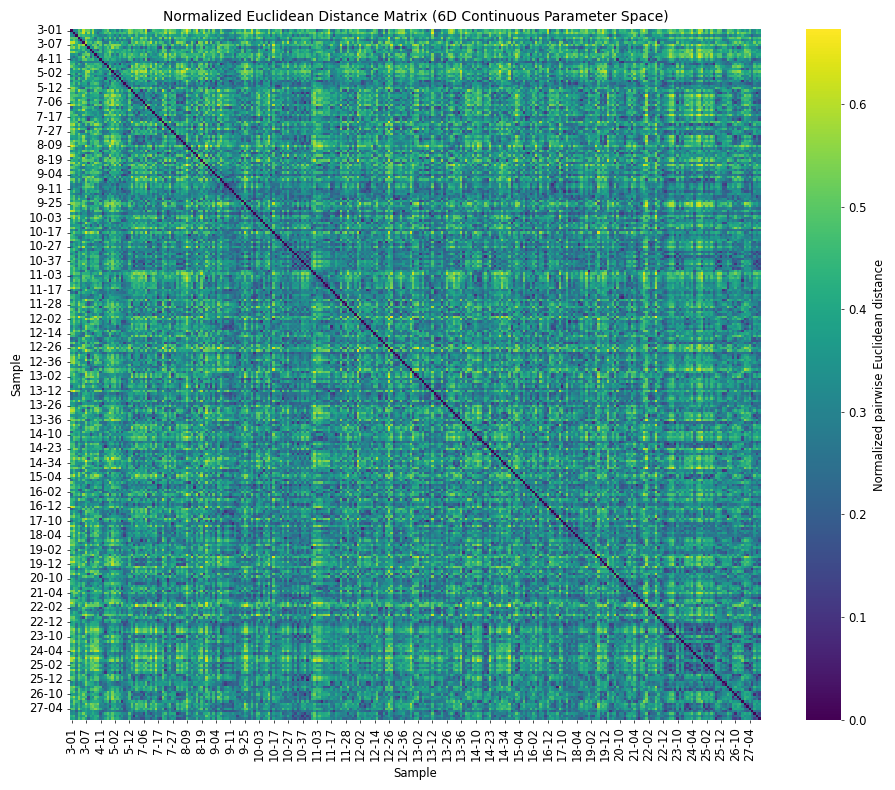

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import MinMaxScaler

# Use the configured continuous columns (expected 6D); fallback to first 6 numeric columns
if "CONTINUOUS_COLUMNS" in globals() and len(CONTINUOUS_COLUMNS) > 0:
    continuous_cols = [
        col for col in CONTINUOUS_COLUMNS if col in df_normalized.columns
    ]
else:
    continuous_cols = df_normalized.select_dtypes(include=[np.number]).columns.tolist()[
        :6
    ]

if len(continuous_cols) != 6:
    raise ValueError(
        f"Expected 6 continuous columns, found {len(continuous_cols)}: {continuous_cols}"
    )

X_norm = df_normalized.copy().reset_index()
X_norm = X_norm.groupby("config_hash").first().set_index("index")
X_norm = X_norm.sort_values(by="sample_name", key=natsort_key)
X_norm = X_norm[continuous_cols]

# Euclidean pairwise distances in 6D, then normalize by max possible distance sqrt(6)
pairwise_d = squareform(pdist(X_norm, metric="euclidean"))
pairwise_d_norm = pairwise_d / np.sqrt(X_norm.shape[1])

# Build labels if sample_name exists
if "sample_name" in df_clean.columns:
    labels = df_clean.loc[X_norm.index, "sample_name"].astype(str).tolist()
else:
    labels = X_norm.index.astype(str).tolist()

dist_df = pd.DataFrame(pairwise_d_norm, index=labels, columns=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    dist_df,
    cmap="viridis",
    vmin=0,
    vmax=np.max(pairwise_d_norm),
    square=True,
    cbar_kws={"label": "Normalized pairwise Euclidean distance"},
)
plt.title("Normalized Euclidean Distance Matrix (6D Continuous Parameter Space)")
plt.xlabel("Sample")
plt.ylabel("Sample")
plt.tight_layout()
plt.show()

In [14]:
if POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE is not None:
    for k, v in POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE.items():
        arr = df[df["a_site"] == k][TARGET_COLUMN].values
        percentile = (np.sum(arr <= v) / len(arr)) * 100
        print(f"A-site: {k}, Threshold: {v}, Percentile: {percentile:.2f}%")

A-site: MBAI, Threshold: 23.1216, Percentile: 85.56%
A-site: MeOMBAI, Threshold: 14.7235, Percentile: 87.95%
A-site: ClMBAI, Threshold: 29.6402, Percentile: 90.23%


## GP Model (Custom Kernel + Fingerprints)

In [15]:
lengthscale_bounds_per_param = None

In [16]:
hps_variance_bounds = np.array([[1e-1, 1e3]])
hps_mean_bounds = np.array([[0.0, 50.0]])
hps_noise_bounds = np.array([[0.1, 50.0]])

sigma_bounds = (
    np.tile(np.array([[1e-1, 1e3]]), (len(fingerprint_metadata.a_sites), 1))
    if sigma_per_chemical
    else np.empty((0, 2))
)

if sigma_per_chemical:
    hps_variance_bounds = np.array([[1.0, 1.0]])

length_scale_bounds = (
    lengthscale_bounds_per_param
    if lengthscale_bounds_per_param is not None
    else np.tile(np.array([[0.05, 1.5]]), (CONTINUOUS_FEATURE_COUNT, 1))
)

hps_bounds = np.vstack(
    [
        hps_variance_bounds,  # Kernel variance
        length_scale_bounds,  # Lengthscales
        np.array([[1.0, 1.0]]),  # FP weight (bounded between 0 and 1)
        sigma_bounds,  # Per-chemical signal variance scales
        hps_noise_bounds,  # Noise
        hps_mean_bounds,  # Mean
    ]
)

init_hyperparameters = np.mean(hps_bounds, axis=1)
init_hyperparameters

array([  1.   ,   0.775,   0.775,   0.775,   0.775,   0.775,   0.775,
         1.   , 500.05 , 500.05 , 500.05 ,  25.05 ,  25.   ])

In [23]:
# Initialize and train the GP prior to Bayesian Optimization
fingerprint_gp = GPOptimizer(
    X_joint,
    y,
    init_hyperparameters=init_hyperparameters,
    kernel_function=kernel_fn,
    prior_mean_function=my_mean,
    noise_function=my_noise,
)

fingerprint_gp.train(
    hyperparameter_bounds=hps_bounds,
    init_hyperparameters=init_hyperparameters,
    method="global",
    max_iter=4000,
)

print("Training complete.")
print(
    "Log Likelihood:",
    fingerprint_gp.log_likelihood(fingerprint_gp.get_hyperparameters()),
)
print(
    "Learned hyperparameters:",
    np.array2string(
        fingerprint_gp.get_hyperparameters(), suppress_small=True, precision=4
    ),
)

results_dir = Path(BASE_DIR, "BO_results_outlier_removed")
if not results_dir.exists():
    results_dir.mkdir(parents=True)

file_name = f"gp_train_results_batch={INITIAL_TRAIN_BATCHES[0]}-{INITIAL_TRAIN_BATCHES[-1]}_target={TARGET_COLUMN}_{'sigma_per_chemical' if sigma_per_chemical else ''}.npz"

save_path = results_dir / file_name

np.savez_compressed(
    save_path,
    train_batches=np.array(INITIAL_TRAIN_BATCHES, dtype=str),
    train_samples=feature_df["sample_name"].to_numpy(dtype=str),
    log_likelihood=fingerprint_gp.log_likelihood(),
    hyperparameters=fingerprint_gp.get_hyperparameters(),
)

print(f"Saved GP training results to {save_path}")

Training complete.
Log Likelihood: -1738.8970399128405
Learned hyperparameters: [ 1.      0.1968  0.3204  0.2654  0.2762  0.3246  0.14    1.     10.6572
  4.9055 14.3292  7.3107  5.7988]
Saved GP training results to G:\Shared drives\Sutter-Fella Lab\ECRP-Project\LPS\BO_results_outlier_removed\gp_train_results_batch=3-27_target=score_sigma_per_chemical.npz


In [17]:
train_result_npz = np.load(
    Path(BASE_DIR)
    / "BO_results_outlier_removed"
    / "gp_train_results_batch=3-27_target=score_sigma_per_chemical.npz"
)

print("Loaded training results:")
print("Train batches:", train_result_npz["train_batches"])
# print("Train samples:", train_result_npz["train_samples"])
print("Log Likelihood:", train_result_npz["log_likelihood"])
print(
    "Hyperparameters:",
    np.array2string(
        train_result_npz["hyperparameters"], suppress_small=True, precision=4
    ),
)

_hps = train_result_npz["hyperparameters"]

print("Re-loaded training results to `kernel_fn`")
# Initialize and train the GP prior to Bayesian Optimization
fingerprint_gp = GPOptimizer(
    X_joint,
    y,
    init_hyperparameters=train_result_npz["hyperparameters"],
    kernel_function=kernel_fn,
    prior_mean_function=my_mean,
    noise_function=my_noise,
)

if np.isclose(
    fingerprint_gp.get_hyperparameters(), train_result_npz["hyperparameters"]
).all():
    print("Hyperparameters successfully loaded to `fingerprint_gp`.")
else:
    print("Warning: Loaded hyperparameters do not match the initialized values.")

if np.isclose(
    fingerprint_gp.log_likelihood(), train_result_npz["log_likelihood"], atol=1
):
    print("Log likelihood of `fingerprint_gp` matches the loaded training result.")
else:
    print(
        "Warning: Log likelihood of `fingerprint_gp` does not match the loaded training result."
    )
    print(
        f"Fingerprint GP log likelihood: {fingerprint_gp.log_likelihood()}, loaded log likelihood: {train_result_npz['log_likelihood']}"
    )

print("Re-loading training results to `kernel_fn_numba`")
# Initialize and train the GP prior to Bayesian Optimization
fingerprint_gp = GPOptimizer(
    X_joint,
    y,
    init_hyperparameters=train_result_npz["hyperparameters"],
    kernel_function=kernel_fn_numba,
    prior_mean_function=my_mean,
    noise_function=my_noise,
)

if np.isclose(
    fingerprint_gp.get_hyperparameters(), train_result_npz["hyperparameters"]
).all():
    print("Hyperparameters successfully loaded to `fingerprint_gp`.")
else:
    print("Warning: Loaded hyperparameters do not match the initialized values.")

if np.isclose(
    fingerprint_gp.log_likelihood(), train_result_npz["log_likelihood"], atol=1
):
    print("Log likelihood of `fingerprint_gp` matches the loaded training result.")
else:
    print(
        "Warning: Log likelihood of `fingerprint_gp` does not match the loaded training result."
    )
    print(
        f"Fingerprint GP log likelihood: {fingerprint_gp.log_likelihood()}, loaded log likelihood: {train_result_npz['log_likelihood']}"
    )

train_result_npz.close()

Loaded training results:
Train batches: ['3' '4' '5' '7' '8' '9' '10' '11' '12' '13' '14' '15' '16' '17' '18' '19'
 '20' '21' '22' '23' '24' '25' '26' '27']
Log Likelihood: -1738.8970399128405
Hyperparameters: [ 1.      0.1968  0.3204  0.2654  0.2762  0.3246  0.14    1.     10.6572
  4.9055 14.3292  7.3107  5.7988]
Re-loaded training results to `kernel_fn`
Hyperparameters successfully loaded to `fingerprint_gp`.
Log likelihood of `fingerprint_gp` matches the loaded training result.
Re-loading training results to `kernel_fn_numba`
Hyperparameters successfully loaded to `fingerprint_gp`.
Log likelihood of `fingerprint_gp` matches the loaded training result.


Training RMSE: 1.961


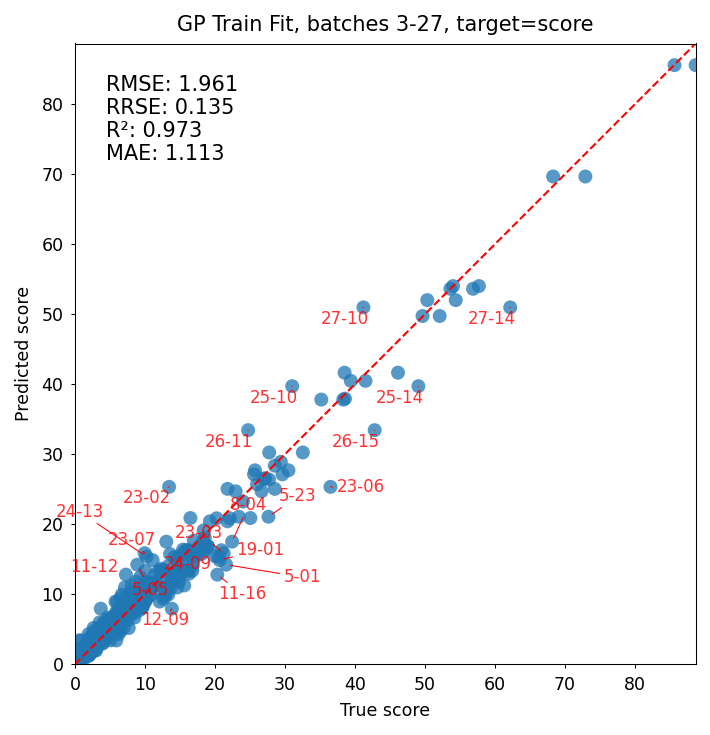

In [24]:
from adjustText import adjust_text

# Training-set prediction diagnostic
# get RMSE of GP predictions on the training data and visualize true vs predicted

train_view = feature_df[["sample_name"]].copy().reset_index(drop=True)
train_view["y_true"] = y
train_view["y_pred"] = fingerprint_gp.posterior_mean(X_joint)["m(x)"]
train_view["error"] = np.abs(train_view["y_true"] - train_view["y_pred"])

rmse_train = np.sqrt(np.mean((train_view["y_true"] - train_view["y_pred"]) ** 2))
rrse_train = np.sqrt(
    np.sum((train_view["y_true"] - train_view["y_pred"]) ** 2)
    / np.sum(train_view["y_true"] ** 2)
)
r2_train = 1 - np.sum((train_view["y_true"] - train_view["y_pred"]) ** 2) / np.sum(
    (train_view["y_true"] - np.mean(train_view["y_true"])) ** 2
)
mae_train = np.mean(np.abs(train_view["y_true"] - train_view["y_pred"]))

fig_text_train = (
    f"RMSE: {rmse_train:.3f}\n"
    f"RRSE: {rrse_train:.3f}\n"
    f"R²: {r2_train:.3f}\n"
    f"MAE: {mae_train:.3f}"
)

fig, ax1 = plt.subplots(figsize=(5, 5), dpi=150)
ax1.scatter(
    train_view["y_true"], train_view["y_pred"], s=45, alpha=0.75, edgecolors="none"
)

line_min = np.min(
    np.concatenate([train_view["y_true"].to_numpy(), train_view["y_pred"].to_numpy()])
)
line_max = np.max(
    np.concatenate([train_view["y_true"].to_numpy(), train_view["y_pred"].to_numpy()])
)
diag_line = np.linspace(line_min, line_max, 100)

large_error_mask = train_view["error"] > (2.5 * rmse_train)
texts = []
for _, row in train_view[large_error_mask].iterrows():
    text = ax1.text(
        row["y_true"],
        row["y_pred"],
        row["sample_name"],
        fontsize=8,
        color="red",
        alpha=0.8,
        ha="center",
        va="center",
    )
    texts.append(text)

if texts:
    adjust_text(texts, arrowprops=dict(arrowstyle="-", color="r", lw=0.5))

ax1.plot(diag_line, diag_line, "r--")
ax1.set_xlim(line_min, line_max)
ax1.set_ylim(line_min, line_max)
ax1.set_aspect("equal", adjustable="box")
ax1.set_xlabel("True score")
ax1.set_ylabel("Predicted score")
ax1.set_title(
    f"GP Train Fit, batches {INITIAL_TRAIN_BATCHES[0]}-{INITIAL_TRAIN_BATCHES[-1]}, target={TARGET_COLUMN}"
)
ax1.text(0.05, 0.95, fig_text_train, transform=ax1.transAxes, verticalalignment="top")
fig.tight_layout()

print(f"Training RMSE: {rmse_train:.3f}")

## Candidate Pool for gp.ask()

Use the helper below to lazily enumerate every combination of the discrete process grid and available A-site fingerprints. It yields normalized feature batches plus their assembled `X_joint` slices so `gp.ask()` can score candidates without materializing the entire Cartesian product in memory.

In [32]:
candidate_iter, (continuous_param_bounds, continuous_param_bounds_norm) = (
    iter_candidate_joint_batches(
        param_config=param_config,
        a_site_to_smiles=A_SITE_TO_SMILES,
        continuous_columns=CONTINUOUS_COLUMNS,
        fingerprint_bits=FINGERPRINT_BITS,
        fingerprint_mode=FINGERPRINT_MODE,
        fingerprint_metadata=fingerprint_metadata,
        include_hash=False,
        batch_size=N_NEW_POINTS * N_IVR_EVAL_BATCH_SIZE,
        n=N_NEW_POINTS * RANDOM_POOL_SIZE,  # request a random subset
        # random_state=42,  # reproducible
        snap=True,  # ensure the values lie on the grid
        replace=True,  # enable repeats
    )
)

print(f"Bounds for continuous parameters (normalized):\n{continuous_param_bounds_norm}")

Bounds for continuous parameters (normalized):
[[0.         1.        ]
 [0.         0.65517241]
 [0.         0.45454545]
 [0.         1.        ]
 [0.         1.        ]
 [0.07894737 0.60526316]]


In [ ]:
from tqdm import tqdm

# estimate number of samples with predicted mean above a_site-specific thresholds
ESTIMATE_POPULATION_SIZE = 10_000_000


def init_iter():
    return iter_candidate_joint_batches(
        param_config=param_config,
        a_site_to_smiles=A_SITE_TO_SMILES,
        continuous_columns=CONTINUOUS_COLUMNS,
        fingerprint_bits=FINGERPRINT_BITS,
        fingerprint_mode=FINGERPRINT_MODE,
        fingerprint_metadata=fingerprint_metadata,
        include_hash=False,
        batch_size=N_NEW_POINTS * N_IVR_EVAL_BATCH_SIZE,
        n=N_NEW_POINTS * RANDOM_POOL_SIZE,  # request a random subset
        # random_state=42,  # reproducible
        snap=True,  # ensure the values lie on the grid
        replace=True,  # enable repeats
    )[0]


n = 0
arrs = []
dfs = []
pred_means = []
itetator = init_iter()

pbar = tqdm(total=ESTIMATE_POPULATION_SIZE)
while n < ESTIMATE_POPULATION_SIZE:
    try:
        df, arr = next(itetator)
    except StopIteration:
        print("Candidate iterator exhausted, re-initializing...")
        print(f"Generated and predicted {n} candidates so far...")
        candidate_iter = init_iter()
        df, arr = next(candidate_iter)
    pred_mean = fingerprint_gp.posterior_mean(arr)["m(x)"]
    arrs.append(arr)
    dfs.append(df)
    pred_means.append(pred_mean)
    n += arr.shape[0]
    pbar.update(arr.shape[0])

pbar.close()

arr_all = np.vstack(arrs)
df_all = pd.concat(dfs, ignore_index=True)
pred_means_all = np.concatenate(pred_means)

df_all["score_min_threshold"] = df_all["a_site"].map(
    POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE
)

mask = pred_means_all >= df_all["score_min_threshold"].to_numpy()
filtered_df = df_all[mask]
print(
    f"Filtered candidate batch from {len(df_all)} to {len(filtered_df)} samples with predicted mean above a_site-specific thresholds."
)

print(df_all[mask].groupby("a_site")["a_site"].count().to_markdown(tablefmt="github"))

In [ ]:
from tqdm import tqdm

# estimate number of samples with predicted mean above a_site-specific thresholds
ESTIMATE_POPULATION_SIZE = 10_000_000
TARGET_PERCENTILE = 99.0


def init_iter():
    return iter_candidate_joint_batches(
        param_config=param_config,
        a_site_to_smiles=A_SITE_TO_SMILES,
        continuous_columns=CONTINUOUS_COLUMNS,
        fingerprint_bits=FINGERPRINT_BITS,
        fingerprint_mode=FINGERPRINT_MODE,
        fingerprint_metadata=fingerprint_metadata,
        include_hash=False,
        batch_size=N_NEW_POINTS * N_IVR_EVAL_BATCH_SIZE,
        n=N_NEW_POINTS * RANDOM_POOL_SIZE,  # request a random subset
        # random_state=42,  # reproducible
        snap=True,  # ensure the values lie on the grid
        replace=True,  # enable repeats
    )[0]


n = 0
arrs = []
dfs = []
itetator = init_iter()

pbar = tqdm(total=ESTIMATE_POPULATION_SIZE)
while n < ESTIMATE_POPULATION_SIZE:
    try:
        df, arr = next(itetator)
    except StopIteration:
        print("Candidate iterator exhausted, re-initializing...")
        print(f"Generated and predicted {n} candidates so far...")
        candidate_iter = init_iter()
        df, arr = next(candidate_iter)
    pred_mean = fingerprint_gp.posterior_mean(arr)["m(x)"]
    arrs.append(arr)
    df["pred_mean"] = pred_mean
    dfs.append(df)
    n += arr.shape[0]
    pbar.update(arr.shape[0])

pbar.close()

df_all = pd.concat(dfs, ignore_index=True)

print(
    f"Estimated {ESTIMATE_POPULATION_SIZE} candidates with predicted means, grouped by a_site with percentile {TARGET_PERCENTILE}:"
)
print(
    df_all.groupby("a_site")["pred_mean"]
    .quantile(TARGET_PERCENTILE / 100.0)
    .to_markdown(tablefmt="github")
)

In [ ]:
def candidate_iter_factory():

    n_steps = RANDOM_POOL_SIZE // N_IVR_EVAL_BATCH_SIZE

    def _init_iter():
        return iter_candidate_joint_batches(
            param_config=param_config,
            a_site_to_smiles=A_SITE_TO_SMILES,
            continuous_columns=CONTINUOUS_COLUMNS,
            fingerprint_bits=FINGERPRINT_BITS,
            fingerprint_mode=FINGERPRINT_MODE,
            fingerprint_metadata=fingerprint_metadata,
            include_hash=False,
            batch_size=N_NEW_POINTS * N_IVR_EVAL_BATCH_SIZE,
            n=N_NEW_POINTS * RANDOM_POOL_SIZE,  # request a random subset
            # random_state=42,  # reproducible
            snap=True,  # ensure the values lie on the grid
            replace=True,  # enable repeats
        )

    if POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE is None:
        candidate_iter, (continuous_param_bounds, continuous_param_bounds_norm) = (
            _init_iter()
        )

        print(
            f"Bounds for continuous parameters (normalized):\n{continuous_param_bounds_norm}"
        )

        return candidate_iter, n_steps

    if set(POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE.keys()) != set(A_SITE_TO_SMILES.keys()):
        raise ValueError(
            f"Keys of posterior_mean_thresholds_by_a_site must match A_SITE_TO_SMILES. Got {POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE.keys()} vs {A_SITE_TO_SMILES.keys()}"
        )

    def generator_with_threshold_filtering():
        candidate_iter, *_ = _init_iter()

        n_per_batch = N_NEW_POINTS * N_IVR_EVAL_BATCH_SIZE
        remainder_df = pd.DataFrame()
        remainder_xs = np.empty((0, X_joint.shape[1]))
        n_valid = 0
        n_total = 0
        for _ in range(n_steps):
            xs_dfs, xss = (
                [
                    remainder_df,
                ],
                [
                    remainder_xs,
                ],
            )
            while n_valid < n_per_batch:
                try:
                    candidate_batch = next(candidate_iter)
                except StopIteration:
                    candidate_iter, *_ = _init_iter()
                    candidate_batch = next(candidate_iter)

                xs_df, xs = candidate_batch

                score_min_threshold_series = xs_df["a_site"].map(
                    POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE
                )
                pred_means = fingerprint_gp.posterior_mean(xs)["m(x)"]
                xs_df["pred_mean"] = pred_means
                mask = pred_means >= score_min_threshold_series.to_numpy()
                xs_dfs.append(xs_df[mask])
                xss.append(xs[mask])
                n_valid += mask.sum()
                n_total += xs.shape[0]

            xs_df_concat = pd.concat(xs_dfs, ignore_index=True)
            xs_concat = np.vstack(xss)
            yield xs_df_concat.iloc[:n_per_batch], xs_concat[:n_per_batch]

            remainder_df = xs_df_concat.iloc[n_per_batch:]
            remainder_xs = xs_concat[n_per_batch:]
            n_valid = len(remainder_df)

    return generator_with_threshold_filtering(), n_steps


candidate_iter, n_steps = candidate_iter_factory()

print(
    f"Candidate iterator with threshold filtering initialized, yielding {n_steps} steps."
)

In [ ]:
class OptimizerBase:
    """Base class for all optimizers"""

    def __init__(self):
        self.name = "BaseOptimizer"

    def optimize(
        self,
        gp_optimizer,
        continuous_bounds,
        kernel,
        n_batch,
        n_fp_dims,
        n_fp_categories=None,
    ):
        """
        Optimize acquisition function to select next batch of points.

        Args:
            gp_optimizer: GPOptimizer instance with current training data
            continuous_bounds: np.array([[lb1, ub1], [lb2, ub2]])
            kernel: Kernel function for acquisition
            n_batch: Number of points to return
            n_fp_dims: Number of fingerprint feature dimensions in X
            n_fp_categories: Optional number of categories for indexed mode

        Returns:
            x_batch: np.array of shape (n_batch, n_continuous + n_fp_dims)
        """
        raise NotImplementedError("Subclasses must implement optimize()")

In [ ]:
from tqdm import tqdm
from joblib import parallel_backend
from chem_informed_mtgp.local_ball_ivr_v3 import local_ball_ivr


class RandomPoolingOptimizer(OptimizerBase):
    """Baseline: Random sampling from search space"""

    def __init__(self, pool_generator, seed=None, radius_multiplier=2.0, n_steps=None):
        self.name = "Random"
        self.pool_generator = pool_generator
        self.rng = np.random.default_rng(seed)
        self.radius_multiplier = radius_multiplier
        self.n_steps = n_steps

    def optimize(
        self,
        gp_optimizer,
        continuous_bounds,
        kernel,
        n_batch,
        n_fp_dims,
        n_fp_categories=None,
        save_ivrs_to_file=None,
    ):
        continuous_bounds = np.array(continuous_bounds)
        n_continuous = len(continuous_bounds)
        n_total_dims = n_continuous + n_fp_dims

        # Indices
        continuous_dims = list(range(n_continuous))

        # Hyperparameters [Signal, L1...Lk, Noise, Mean]
        ls_indices = [i + 1 for i in range(n_continuous)]
        noise_index = -2
        signal_index = 0

        if n_fp_dims > 0:
            if n_fp_dims == 1 and n_fp_categories is not None:
                fp_bounds = np.array([[0.0, float(n_fp_categories - 1)]], dtype=float)
            else:
                fp_bounds = np.tile([0.0, 1.0], (n_fp_dims, 1))
            full_bounds = np.vstack([continuous_bounds, fp_bounds])
        else:
            full_bounds = continuous_bounds

        # Pre-compute training data cache (Cholesky factorization) to avoid race conditions
        print("Pre-computing training data cache...")
        _cache = {}
        dummy_batch = np.zeros((1, n_batch, n_total_dims))
        _ = local_ball_ivr(
            x=dummy_batch,
            gp_optimizer=gp_optimizer,
            bounds=full_bounds,
            kernel_func=kernel,
            ls_indices=ls_indices,
            noise_index=noise_index,
            signal_index=signal_index,
            continuous_indices=continuous_dims,
            _cache=_cache,
            use_parallel=False,  # Disable Numba parallelization for cache warmup
            use_batch_parallel=False,
        )
        print(f"Cache pre-computed. Keys: {list(_cache.keys())}")

        def get_joint_ivr(batch_x):
            return local_ball_ivr(
                x=batch_x,
                gp_optimizer=gp_optimizer,
                bounds=full_bounds,
                kernel_func=kernel,
                ls_indices=ls_indices,
                noise_index=noise_index,
                signal_index=signal_index,
                continuous_indices=continuous_dims,
                n_samples_per_group=500,
                radius_multiplier=self.radius_multiplier,
                use_batch_parallel=True,  # Enable parallel batch processing
                _cache=_cache,  # Pre-computed cache shared at fork time
                n_jobs=N_CPU,
                use_parallel=False,  # Disable Numba parallelization within each batch to avoid oversubscription
            )

        best_ivr = -np.inf
        best_batch = (None, None)

        if self.n_steps is not None:
            n_steps = self.n_steps
        else:
            n_steps = RANDOM_POOL_SIZE // N_IVR_EVAL_BATCH_SIZE

        # Create persistent process pool to avoid repeated spawn overhead
        with parallel_backend(backend="loky", n_jobs=N_CPU):
            for xs_df, xs in tqdm(
                self.pool_generator, desc="Evaluating random candidates", total=n_steps
            ):
                max_index = (len(xs) // n_batch) * n_batch
                batch_candidates = xs[:max_index].reshape(-1, n_batch, n_total_dims)
                ivrs = get_joint_ivr(batch_candidates)
                batch_best_idx = np.argmax(ivrs)
                batch_best_ivr = ivrs[batch_best_idx]

                if batch_best_ivr > best_ivr:
                    best_ivr = batch_best_ivr
                    best_df = xs_df.iloc[
                        batch_best_idx * n_batch : (batch_best_idx + 1) * n_batch
                    ]
                    best_batch = (best_df, batch_candidates[batch_best_idx])

                if save_ivrs_to_file is not None:
                    xs_df_trimmed = xs_df.iloc[:max_index].copy()
                    xs_df_trimmed["candidate_batch_idx"] = (
                        xs_df_trimmed.index // n_batch
                    )
                    xs_df_trimmed["ivr"] = ivrs.repeat(n_batch)
                    write_header = not Path(save_ivrs_to_file).exists()
                    xs_df_trimmed.to_csv(
                        save_ivrs_to_file, header=write_header, mode="a"
                    )

        return best_batch, best_ivr


optimizer = RandomPoolingOptimizer(
    pool_generator=candidate_iter, radius_multiplier=2.0, n_steps=n_steps
)

In [ ]:
timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")

csv_path = (
    Path(BASE_DIR, "BO_results_outlier_removed")
    / f"{timestamp}_best_batch_n={N_NEW_POINTS}.csv"
)

(best_df, best_x), best_ivr = optimizer.optimize(
    gp_optimizer=fingerprint_gp,
    continuous_bounds=continuous_param_bounds_norm,
    kernel=kernel_fn_numba,
    n_batch=N_NEW_POINTS,
    n_fp_dims=FP_FEATURE_DIMS,
    n_fp_categories=len(A_SITE_TO_SMILES) if FP_FEATURE_DIMS == 1 else None,
    # save_ivrs_to_file=csv_path.with_suffix(".ivrs.csv"),
)

if not isinstance(best_df, pd.DataFrame):
    raise ValueError("Expected best_df to be a DataFrame, got {}".format(type(best_df)))


with open(csv_path, "w") as f:
    f.write(f"# Optimizer: {optimizer.name}\n")
    f.write(f"# Timestamp: {timestamp}\n")
    f.write(f"# Training data batches: {INITIAL_TRAIN_BATCHES}\n")
    f.write(f"# Excluded samples: {outliers_by_sample_name}\n")
    f.write(f"# Requested batch size: {N_NEW_POINTS}, pool size: {RANDOM_POOL_SIZE}\n")
    if POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE is not None:
        f.write(
            f"# Posterior mean thresholds by a_site: {json.dumps(POSTERIOR_MEAN_THRESHOLDS_BY_A_SITE)}\n"
        )
    f.write(f"# IVR: {best_ivr:.4f}\n")
    f.write(
        f"# Hyperparameters: {np.array2string(fingerprint_gp.get_hyperparameters(), suppress_small=True, precision=4, max_line_width=1000)}\n"
    )

best_df.to_csv(csv_path, index=False, mode="a")

print("\nBest candidate batch, IVR=", best_ivr)
print(best_df[CONTINUOUS_COLUMNS + ["a_site"]].to_markdown(tablefmt="github"))

In [ ]:
# read save_ivrs_to_file, grouped by candidate_bach_idx, plot hist of ivr
ivr_df = pd.read_csv(csv_path.with_suffix(".ivrs.csv"))
sns.histplot(data=ivr_df.groupby("candidate_batch_idx").first(), x="ivr", bins=20)
plt.show()
if "pred_mean" in ivr_df.columns and "a_site" in ivr_df.columns:
    sns.histplot(data=ivr_df, x="pred_mean", hue="a_site", bins=20)
    plt.show()

## Next Steps

1. Port the Bayesian optimization loop from the original notebook and wire it to `fingerprint_gp`'s kernel and acquisition logic.
2. Replace the placeholder data fallbacks with the production query/IO pipeline once access to the LPS database is available.
3. Experiment with alternative fingerprint widths or chem-informed featurizers by overriding `FINGERPRINT_BITS` before re-running the pipeline.

In [33]:
# Train GP models on sequential batch combinations and save results


from joblib import Parallel, delayed

# Define batch configurations
# INITIAL_TRAIN_BATCHES = ["3", "4", "5"]
# SEQUENTIAL_TRAIN_BATCHES = ["7", "8", "9", "10", "11", "12", "13", "14"]

INITIAL_TRAIN_BATCHES = [
    "3",
    "4",
    "5",
    "7",
    "8",
]
SEQUENTIAL_TRAIN_BATCHES = [
    "9",
    "10",
    "11",
    "12",
    "13",
    "14",
    "15",
    "16",
    "17",
    "18",
    "19",
    "20",
    "21",
    "22",
    "23",
    "24",
    "25",
    "26",
    "27",
]

results_dir = Path(BASE_DIR, r"BO_results_outlier_removed")

if not results_dir.exists():
    results_dir.mkdir(parents=True)
    print(f"Created results directory: {results_dir}")


def train_gp(train_batches):
    """
    Train GP for a single batch combination and save results.
    """

    print(f"\n=== Training on batches: {train_batches} ===")

    feature_df = df_normalized.copy()

    train_rows = feature_df["sample_name"].str.split("-").str[0].isin(
        train_batches
    ) & ~feature_df["sample_name"].isin(outliers_by_sample_name)
    feature_df = feature_df.loc[train_rows].reset_index(drop=True)

    X_joint = assemble_feature_matrix(
        df=feature_df,
        continuous_columns=CONTINUOUS_COLUMNS,
        fingerprint_column="a_site_smiles",
        n_bits=FINGERPRINT_BITS,
        fingerprint_mode=FINGERPRINT_MODE,
        fingerprint_metadata=fingerprint_metadata,
        a_site_column="a_site",
    )
    y = feature_df[TARGET_COLUMN].to_numpy(dtype=np.float64)

    gp = GPOptimizer(
        X_joint,
        y,
        init_hyperparameters=init_hyperparameters,
        kernel_function=kernel_fn,
        prior_mean_function=my_mean,
        noise_function=my_noise,
    )

    gp.train(
        hyperparameter_bounds=hps_bounds,
        init_hyperparameters=init_hyperparameters,
        method="global",
        max_iter=2000,
    )

    # Save results
    save_path = (
        results_dir
        / f"gp_train_results_batch={train_batches[0]}-{train_batches[-1]}.npz"
    )
    # np.savez_compressed(
    #     save_path,
    #     train_batches=np.array(train_batches, dtype=str),
    #     train_samples=feature_df["sample_name"].to_numpy(dtype=str),
    #     log_likelihood=gp.log_likelihood(),
    #     hyperparameters=gp.get_hyperparameters(),
    # )
    print(f"Saved results to {save_path}")

    return save_path


results = Parallel(n_jobs=-2, backend="loky")(
    delayed(train_gp)(INITIAL_TRAIN_BATCHES + SEQUENTIAL_TRAIN_BATCHES[:i])
    for i in range(len(SEQUENTIAL_TRAIN_BATCHES) + 1)
)

print(f"\nCompleted all {len(results)} training iterations")
print(f"Saved files: {results}")


Completed all 20 training iterations
Saved files: [WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-8.npz'), WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-9.npz'), WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-10.npz'), WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-11.npz'), WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-12.npz'), WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-13.npz'), WindowsPath('G:/Shared drives/Sutter-Fella Lab/ECRP-Project/Yi-Ru/LPS/BO_results_outlier_removed/gp_train_results_batch=3-14.npz'), WindowsPath('G:/Shared dri

In [ ]:
from joblib import Parallel, delayed
from chem_informed_mtgp.kl_div_gpu import kl_div_gpu
from natsort import natsorted
from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================================
# CONFIGURATION
# ============================================================================

INITIAL_TRAIN_BATCHES = [
    "3",
    "4",
    "5",
    "7",
    "8",
]
SEQUENTIAL_TRAIN_BATCHES = [
    "9",
    "10",
    "11",
    "12",
    "13",
    "14",
    "15",
    "16",
    "17",
    "18",
    "19",
    "20",
    "21",
    "22",
    "23",
    "24",
    "25",
    "26",
    "27",
]

KL_DIV_MC_SAMPLES = 1_000
KL_DIV_MC_REPEATS = 50

# Directory configuration
results_dir = Path(BASE_DIR, r"BO_results_outlier_removed")
repeat_results_dir = Path(
    f"./temp/kl_posterior_outlier_removed_n={KL_DIV_MC_SAMPLES}x{KL_DIV_MC_REPEATS}"
)
repeat_results_dir.mkdir(parents=True, exist_ok=True)


# ============================================================================
# HELPER FUNCTIONS
# ============================================================================


def candidate_iter_factory():
    return iter_candidate_joint_batches(
        param_config=param_config,
        a_site_to_smiles=A_SITE_TO_SMILES,
        continuous_columns=CONTINUOUS_COLUMNS,
        fingerprint_bits=FINGERPRINT_BITS,
        fingerprint_mode=FINGERPRINT_MODE,
        fingerprint_metadata=fingerprint_metadata,
        include_hash=False,
        batch_size=KL_DIV_MC_SAMPLES,
        n=KL_DIV_MC_SAMPLES * KL_DIV_MC_REPEATS,
        random_state=42,  # reproducible
        snap=False,  # ensure the values lie on the grid
        replace=False,  # no repeats within each batch
    )[0]


def build_gp_for_batches(train_batches, hps):
    feature_df = df_normalized.copy()

    train_rows = feature_df["sample_name"].str.split("-").str[0].isin(
        train_batches
    ) & ~feature_df["sample_name"].isin(outliers_by_sample_name)
    feature_df = feature_df.loc[train_rows].reset_index(drop=True)

    X_joint = assemble_feature_matrix(
        df=feature_df,
        continuous_columns=CONTINUOUS_COLUMNS,
        fingerprint_column="a_site_smiles",
        n_bits=FINGERPRINT_BITS,
        fingerprint_mode=FINGERPRINT_MODE,
        fingerprint_metadata=fingerprint_metadata,
        a_site_column="a_site",
    )
    y = feature_df[TARGET_COLUMN].to_numpy(dtype=np.float64)

    gp = GPOptimizer(
        X_joint,
        y,
        init_hyperparameters=hps,
        kernel_function=kernel_fn,
        prior_mean_function=my_mean,
        noise_function=my_noise,
    )
    return gp


def batch_tag(train_batches):
    return f"{train_batches[0]}-{train_batches[-1]}"


def collect_test_batches(n_repeats):
    candidate_iter = candidate_iter_factory()
    x_test_batches = []
    for repeat_idx, (_, x_test) in enumerate(candidate_iter):
        if repeat_idx >= n_repeats:
            break
        x_test_batches.append(np.asarray(x_test, dtype=np.float32))

    if len(x_test_batches) != n_repeats:
        raise ValueError(
            f"Expected {n_repeats} test batches, got {len(x_test_batches)} from candidate iterator."
        )
    return x_test_batches


def load_posterior_metadata(results_dir):
    """Load metadata from posterior result files."""
    posterior_files = natsorted(results_dir.glob("gp_train_results_batch=*.npz"))
    if len(posterior_files) < 1:
        raise FileNotFoundError(
            f"Need at least 1 posterior result file in {results_dir}; found {len(posterior_files)}."
        )

    analysis_data = []
    for file in posterior_files:
        data = np.load(file, allow_pickle=True)
        analysis_data.append(
            {
                "file": file.name,
                "train_batches": data["train_batches"].astype(str).tolist(),
                "log_likelihood": float(data["log_likelihood"]),
                "hyperparameters": np.asarray(
                    data["hyperparameters"], dtype=np.float64
                ),
            }
        )
        data.close()

    analysis_df = pd.DataFrame(analysis_data)
    return analysis_df


# ============================================================================
# STEP 1: LOAD METADATA & BUILD GPs
# ============================================================================

analysis_df = load_posterior_metadata(results_dir)
print("Loaded batch metadata from:")
print(analysis_df[["file"]].to_markdown(tablefmt="github", index=False))

# Collect test candidates once
x_test_batches = collect_test_batches(KL_DIV_MC_REPEATS)
print(
    f"Prepared {len(x_test_batches)} x_test batches, each with shape {x_test_batches[0].shape}."
)

# Build GPOptimizer for each training batch combination
batch_gps = {}
ordered_batch_tags = []
for row in analysis_df.itertuples(index=False):
    tag = batch_tag(row.train_batches)
    gp = build_gp_for_batches(row.train_batches, row.hyperparameters)
    batch_gps[tag] = gp
    ordered_batch_tags.append(tag)
    print(f"Initialized GP for batch tag: {tag}")

print(f"\nTotal batch tags prepared: {len(ordered_batch_tags)}")

Loaded batch metadata from:
| file                                         |
|----------------------------------------------|
| gp_train_results_batch=3-5.npz               |
| gp_train_results_batch=3-7.npz               |
| gp_train_results_batch=3-8.npz               |
| gp_train_results_batch=3-9.npz               |
| gp_train_results_batch=3-10.npz              |
| gp_train_results_batch=3-11.npz              |
| gp_train_results_batch=3-12.npz              |
| gp_train_results_batch=3-13.npz              |
| gp_train_results_batch=3-14.npz              |
| gp_train_results_batch=3-15.npz              |
| gp_train_results_batch=3-16.npz              |
| gp_train_results_batch=3-17.npz              |
| gp_train_results_batch=3-18.npz              |
| gp_train_results_batch=3-19.npz              |
| gp_train_results_batch=3-20_target=score.npz |
| gp_train_results_batch=3-21_target=score.npz |
| gp_train_results_batch=3-22_target=score.npz |
| gp_train_results_batch=3-23_target=scor

In [ ]:
# ============================================================================
# STEP 2: COMPUTE & SAVE POSTERIOR/COVARIANCE FOR SELECTED BATCHES
# ============================================================================
# This can be run independently for specific batches without running all of them.

from tqdm import tqdm
import sys


def compute_and_save_repeats_for_batch(
    tag, gp, x_batches, output_dir=repeat_results_dir
):
    """
    Compute posterior and covariance for a single batch across all repeats.

    Parameters:
    -----------
    tag : str
        Batch tag (e.g., "3-5")
    gp : GPOptimizer
        Trained GP for this batch
    x_batches : list of arrays
        List of test candidate batches
    output_dir : Path
        Directory to save posterior_cov_batch_{tag}_repeat_{repeat_idx:02d}.npz files

    Returns:
    --------
    list of Path
        Paths to saved npz files
    """

    def _one_repeat(repeat_idx, x_test):
        posterior = gp.posterior_mean(x_test)["m(x)"].astype(np.float32)
        covariance = gp.posterior_covariance(x_test)["S"].astype(np.float32)
        save_path = (
            output_dir / f"posterior_cov_batch={tag}_repeat={repeat_idx:02d}.npz"
        )
        np.savez(
            save_path,
            batch_tag=tag,
            repeat_idx=repeat_idx,
            posterior=posterior,
            covariance=covariance,
        )
        return save_path

    with Parallel(n_jobs=14) as parallel:
        saved_files = parallel(
            delayed(_one_repeat)(repeat_idx, x_test)
            for repeat_idx, x_test in enumerate(x_batches)
        )
    return saved_files


# Specify which batches to compute posteriors for (or compute all)
# Option 1: Compute for all batches
tags_to_compute = ordered_batch_tags.copy()

# Option 2 (uncomment to use): Compute only for specific batches
# tags_to_compute = ["3-22"]  # Example: only initial and final batches

print(f"Computing posteriors for {len(tags_to_compute)} batch tag(s)...")
all_repeat_files = {}
for tag in tqdm(tags_to_compute, file=sys.stdout):
    if tag not in batch_gps:
        raise ValueError(
            f"Batch tag '{tag}' not found in batch_gps. Available: {list(batch_gps.keys())}"
        )
    saved = compute_and_save_repeats_for_batch(tag, batch_gps[tag], x_test_batches)
    all_repeat_files[tag] = saved
    tqdm.write(f"✓ Saved {len(saved)} repeat files for batch: {tag}", file=sys.stdout)


print(f"\nAll posterior/covariance files saved to: {repeat_results_dir}")
print("Files can be loaded as: posterior_cov_batch={tag}_repeat={repeat_idx:02d}.npz")

In [ ]:
# ============================================================================
# STEP 3: COMPUTE KL DIVERGENCE BETWEEN SELECTED BATCH PAIRS
# ============================================================================
# This step can be run independently on any set of batch pairs.
# Requires that posterior_cov_batch files are already saved from STEP 2.


def compute_kl_divergence_for_pairs(
    batch_pairs, repeat_indices=None, output_dir=repeat_results_dir
):
    """
    Compute KL divergence between specified batch pairs.

    Parameters:
    -----------
    batch_pairs : list of tuples
        List of (batch_a, batch_b) tuples to compare
        Example: [("3-5", "3-6"), ("3-6", "7-9")]
    repeat_indices : list of int, optional
        Which repeats to use. If None, uses all available (0 to KL_DIV_MC_REPEATS-1)
    output_dir : Path
        Directory where posterior_cov files are stored

    Returns:
    --------
    pd.DataFrame
        Results with columns: batch_a, batch_b, kl_div, kl_div_std, kl_div_sem, kl_div_per_repeat
    """
    if repeat_indices is None:
        repeat_indices = range(KL_DIV_MC_REPEATS)

    kl_rows = []
    for tag_a, tag_b in tqdm(batch_pairs, desc="Computing KL divergence"):
        repeat_kls = []
        for repeat_idx in repeat_indices:
            file_a = (
                output_dir / f"posterior_cov_batch={tag_a}_repeat={repeat_idx:02d}.npz"
            )
            file_b = (
                output_dir / f"posterior_cov_batch={tag_b}_repeat={repeat_idx:02d}.npz"
            )

            # Check files exist
            if not file_a.exists():
                raise FileNotFoundError(f"Missing: {file_a}")
            if not file_b.exists():
                raise FileNotFoundError(f"Missing: {file_b}")

            data_a = np.load(file_a)
            data_b = np.load(file_b)

            post_a = data_a["posterior"]
            cov_a = data_a["covariance"]
            post_b = data_b["posterior"]
            cov_b = data_b["covariance"]

            kl_div = float(kl_div_gpu(post_a, post_b, cov_a, cov_b, rank=-1))
            repeat_kls.append(kl_div)

            data_a.close()
            data_b.close()

        kl_rows.append(
            {
                "batch_a": tag_a,
                "batch_b": tag_b,
                "kl_div": float(np.mean(repeat_kls)),
                "kl_div_std": float(np.std(repeat_kls)),
                "kl_div_sem": float(np.std(repeat_kls) / np.sqrt(len(repeat_kls))),
                "kl_div_per_repeat": repeat_kls,
            }
        )

    return pd.DataFrame(kl_rows)


# ============================================================================
# CONFIGURATION: Specify which batch pairs to compare
# ============================================================================

# Option 1: Compare consecutive batch pairs (original behavior)
batch_pairs_to_compare = [
    (ordered_batch_tags[i], ordered_batch_tags[i + 1])
    for i in range(len(ordered_batch_tags) - 1)
]

# Use batch 1 as baseline and compare to all subsequent batches
# batch_pairs_to_compare = [
#     (ordered_batch_tags[0], ordered_batch_tags[i + 1])
#     for i in range(len(ordered_batch_tags) - 1)
# ]

# Option 2 (uncomment to use): Compare specific pairs only
# batch_pairs_to_compare = [
#     ("3-5", "3-6"),
#     ("3-6", "7-9"),
#     ("3-5", "7-9"),  # Can compare non-consecutive
# ]

# Option 3 (uncomment to use): Compare all pairs (combinatorial)
# ruff: noqa: E402
# from itertools import combinations
# batch_pairs_to_compare = list(combinations(ordered_batch_tags, 2))

print(f"Computing KL divergence for {len(batch_pairs_to_compare)} batch pair(s):")
for tag_a, tag_b in batch_pairs_to_compare:
    print(f"  {tag_a} vs {tag_b}")

# Run KL divergence computation
results_df = compute_kl_divergence_for_pairs(
    batch_pairs_to_compare,
    repeat_indices=None,  # Use all repeats
    output_dir=repeat_results_dir,
)

print("\n" + "=" * 80)
print("KL Divergence Results:")
print("=" * 80)
print(
    results_df[
        ["batch_a", "batch_b", "kl_div", "kl_div_std", "kl_div_sem"]
    ].to_markdown(tablefmt="github", index=False, floatfmt=".3f")
)

# Save results to CSV
timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
detailed_path = results_dir / f"{timestamp}_kl_div_results.csv"
with open(detailed_path, "w") as f:
    f.write("# KL Divergence results for batch comparisons\n")
    f.write(f"# Timestamp: {timestamp}\n")
    f.write(f"# Batch pairs compared: {len(batch_pairs_to_compare)}\n")
    f.write(
        f"# MC samples per repeat: {KL_DIV_MC_SAMPLES}, repeats per pair: {KL_DIV_MC_REPEATS}\n"
    )

results_df.to_csv(detailed_path, index=False, mode="a")
print(f"\n✓ Saved KL divergence results to:\n  {detailed_path}")